# ASI background-subtraction diagnostic

Inspect the exact background selection and calibration used by `map_asi_archive.py`.
Change the camera, color, or UTC below and run all cells. The default is VEE blue at 2026-02-10 10:24:00 UTC.

The pipeline estimates one background DN value per frame from buffered outer pixels, subtracts it everywhere, then converts to Rayleighs. It does not subtract a spatial bias image or sky-background gradient. Raw arrays remain unchanged; image contrast limits below are display-only.

In [1]:
from pathlib import Path
import sys
import datetime as dt
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, TwoSlopeNorm

# Works with a kernel started in the repository or comparisons directory.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "core/calibration.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from core import calibration
from core.skymaps import load_skymaps
from core.tiff_utils import get_site_tiff_candidates, load_best_frame_from_tiffs
from core.constants import FRAME_INTERVAL_SECONDS_GREEN, FRAME_INTERVAL_SECONDS_RED


In [2]:
SITE = "VEE"                  # ARV, BVR, VEE
COLOR = "blue"                # green, red, blue
DATE = "20260210"
UTC = "102400"
EDGE_BUFFER_PX = calibration.BACKGROUND_EDGE_BUFFER_PX  # production default: 80

assert SITE in {"ARV", "BVR", "VEE"}
assert COLOR in {"green", "red", "blue"}
assert EDGE_BUFFER_PX >= 0
TARGET = dt.datetime.strptime(DATE + UTC, "%Y%m%d%H%M%S")
CADENCE = {"green": FRAME_INTERVAL_SECONDS_GREEN, "red": FRAME_INTERVAL_SECONDS_RED, "blue": 0.90178}[COLOR]


## Load a real frame and its starmap
The mapper's loader prints the selected TIFF, frame index, timing difference, and timing metadata source. Acquisition cadence selects the frame; exposure duration controls radiometric calibration. These are distinct quantities.

In [3]:
skymap = load_skymaps({SITE}, color=COLOR, mission="GNEISS")[SITE]
paths = get_site_tiff_candidates(SITE, DATE, COLOR, mission="GNEISS")
if not paths:
    raise FileNotFoundError(f"No {COLOR} TIFFs available for {SITE} on {DATE}")
raw, _ = load_best_frame_from_tiffs(SITE, paths, TARGET, CADENCE, color=COLOR)
raw = np.asarray(raw)
excluded = np.asarray(skymap["mask"], dtype=bool)
assert raw.shape == excluded.shape, (raw.shape, excluded.shape)
background_mask = calibration.buffered_corner_mask(excluded, EDGE_BUFFER_PX)
calibrated, bg = calibration.calibrate_image(SITE, raw, excluded, COLOR, edge_buffer_px=EDGE_BUFFER_PX)
if calibrated is None:
    raise ValueError(f"No calibration configured for {SITE} {COLOR}")
corrected_dn = raw.astype(np.float32) - bg["center"]
factor = calibration.calibration_factor(SITE, COLOR)
exposure = calibration.exposure_time_s(COLOR)
print(f"{SITE} {COLOR}, requested UTC {TARGET}; shape={raw.shape}, dtype={raw.dtype}")
print(f"Background pixels: {bg['n_pixels']:,}; buffer: {EDGE_BUFFER_PX:g} px")
print(f"Background: {bg['center']:.4f} DN; median: {bg['median']:.4f} DN; sigma: {bg['sigma']:.4f} DN")
print("Estimator:", "median fallback (fit rejected/failed or constant data)" if bg["fit_failed"] else "Gaussian histogram fit")
print(f"Rayleighs = (DN - {bg['center']:.4f}) × {factor:g} / {exposure:g}")
np.testing.assert_allclose(calibrated, corrected_dn / exposure * factor, rtol=1e-6, atol=1e-5)


VEE: SOK260210_09595922_16bit.tif frame 1598/3991 (delta 0.15s, metadata /Users/anniepflaum/lab317/data/raw/asi/images/blue/VEE/SOK260210_09595922_16bit.log)


VEE blue, requested UTC 2026-02-10 10:24:00; shape=(512, 512), dtype=float32
Background pixels: 54,609; buffer: 80 px
Background: 110.1752 DN; median: 110.0000 DN; sigma: 5.6070 DN
Estimator: Gaussian histogram fit
Rayleighs = (DN - 110.1752) × 40 / 0.9


## Which pixels estimate the background?
The elevation mask excludes pixels below 22°. The distance transform then selects excluded pixels **more than 80 pixels from the usable region**, not an 80-pixel border around the detector. The background selection below is exactly the mask passed to the estimator.

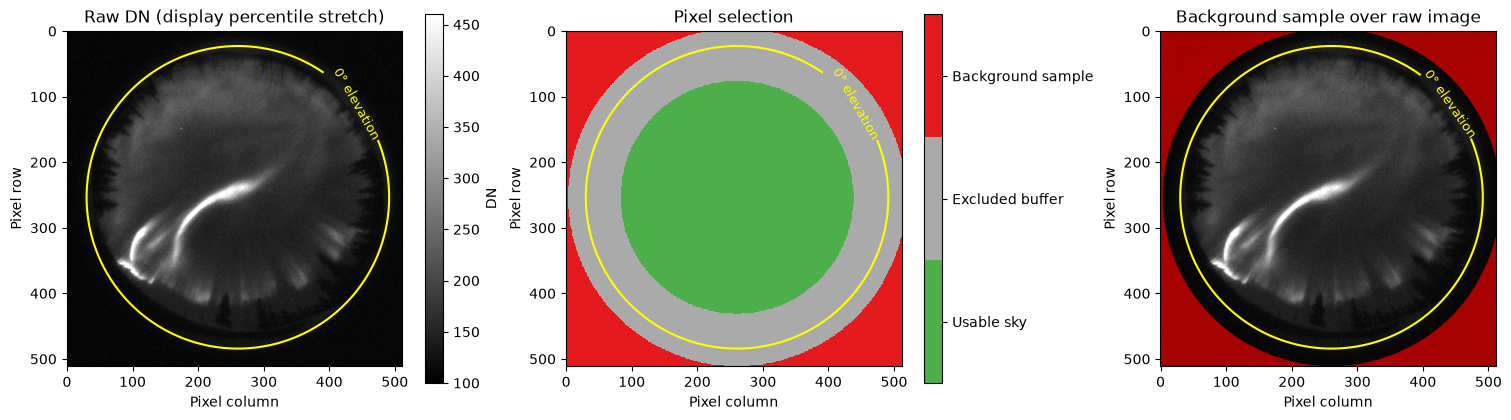

In [4]:
finite = raw[np.isfinite(raw)]
lo, hi = np.percentile(finite, [1, 99.7])
fig, axes = plt.subplots(1, 3, figsize=(15, 5), layout="constrained")
im = axes[0].imshow(raw, cmap="gray", vmin=lo, vmax=hi, origin="upper")
axes[0].set_title("Raw DN (display percentile stretch)")
fig.colorbar(im, ax=axes[0], label="DN", shrink=.75)
regions = np.where(background_mask, 2, np.where(excluded, 1, 0))
im = axes[1].imshow(regions, cmap=ListedColormap(["#4daf4a", "#aaaaaa", "#e41a1c"]), vmin=-.5, vmax=2.5, interpolation="nearest")
axes[1].set_title("Pixel selection")
cb = fig.colorbar(im, ax=axes[1], ticks=[0, 1, 2], shrink=.75)
cb.ax.set_yticklabels(["Usable sky", "Excluded buffer", "Background sample"])
axes[2].imshow(raw, cmap="gray", vmin=lo, vmax=hi)
overlay = np.zeros((*raw.shape, 4))
overlay[background_mask] = [1, 0, 0, .65]
axes[2].imshow(overlay)
axes[2].set_title("Background sample over raw image")
# Horizon from this camera's actual starmap, in detector pixel coordinates.
elevation = np.ma.masked_invalid(np.asarray(skymap["elev"], dtype=float))
for ax in axes:
    horizon = ax.contour(elevation, levels=[0.0], colors="yellow", linewidths=1.5)
    ax.clabel(horizon, fmt={0.0: "0° elevation"}, inline=True, fontsize=9)
    ax.set_xlabel("Pixel column")
    ax.set_ylabel("Pixel row")
plt.show()


## DN histogram and fitted center
Use the same histogram bins as the production estimator. The orange curve shows the returned Gaussian center and width, normalized to the histogram area for visualization (the production fit's amplitude is not returned). If the estimator falls back to the median, no fitted curve is shown. Sigma is diagnostic; it is not subtracted.

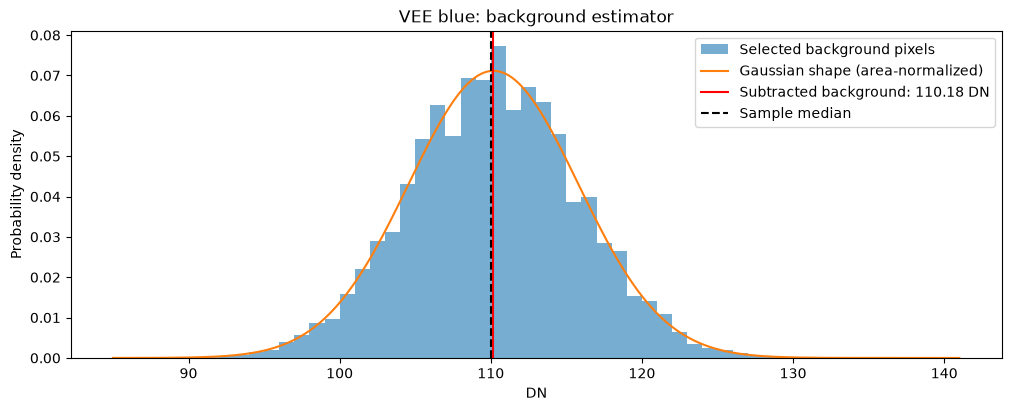

In [5]:
values = calibration.finite_values(raw[background_mask])
bins = np.arange(np.floor(values.min()), np.ceil(values.max()) + 1)
if bins.size < 3:
    bins = np.linspace(values.min(), values.max() + 1, 3)
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
ax.hist(values, bins=bins, density=True, alpha=.6, label="Selected background pixels")
if not bg["fit_failed"] and bg["sigma"] > 0:
    x = np.linspace(bins[0], bins[-1], 2000)
    y = calibration.gauss(x, 1 / (np.sqrt(2*np.pi)*bg["sigma"]), bg["center"], bg["sigma"])
    ax.plot(x, y, color="tab:orange", label="Gaussian shape (area-normalized)")
ax.axvline(bg["center"], color="red", label=f"Subtracted background: {bg['center']:.2f} DN")
ax.axvline(bg["median"], color="black", linestyle="--", label="Sample median")
ax.set(xlabel="DN", ylabel="Probability density", title=f"{SITE} {COLOR}: background estimator")
ax.legend()
plt.show()


## Subtraction and Rayleigh conversion
The first two images share identical DN limits so the offset change is visible. The third uses a symmetric scale to show negative residuals; these values are retained. The final panel shows the calibrated usable-sky region on a linear scale. The map's logarithmic display cannot show nonpositive intensities.

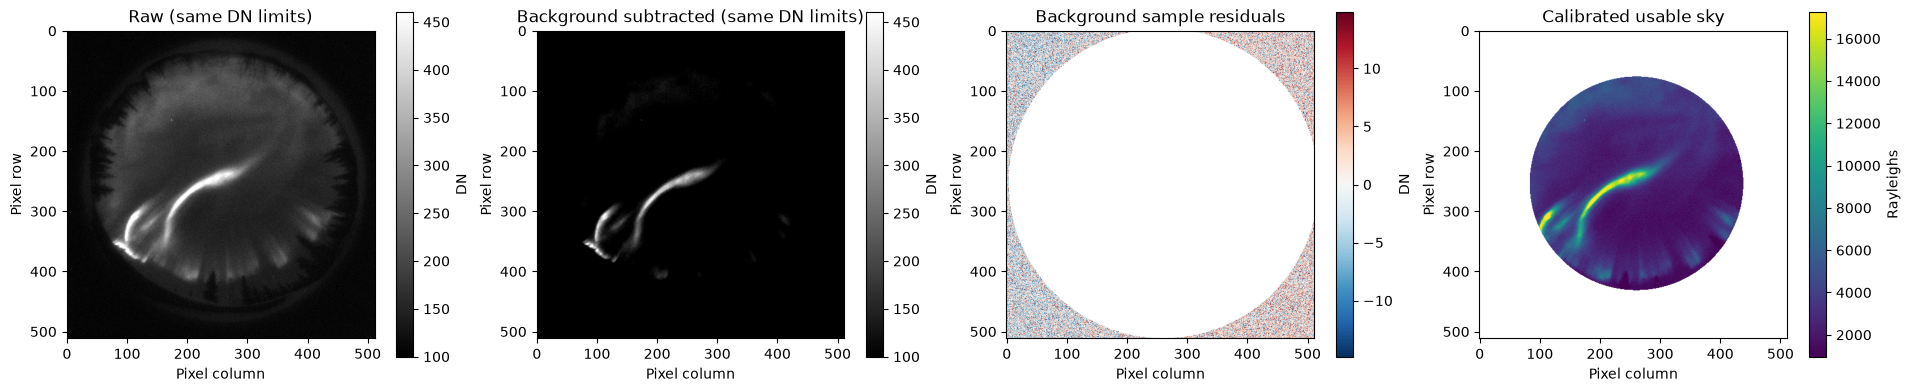

Usable-sky pixels ≤ 0 R: 0.03%
Background sample residual median: -0.1752 DN


In [6]:
fig, axes = plt.subplots(1, 4, figsize=(19, 5), layout="constrained")
for ax, arr, title in zip(axes[:2], [raw, corrected_dn], ["Raw", "Background subtracted"]):
    im = ax.imshow(arr, cmap="gray", vmin=lo, vmax=hi)
    ax.set_title(title + " (same DN limits)")
    fig.colorbar(im, ax=ax, label="DN", shrink=.7)
residual = np.where(background_mask, corrected_dn, np.nan)
span = max(float(np.nanpercentile(np.abs(residual), 99)), 1.)
im = axes[2].imshow(residual, cmap="RdBu_r", norm=TwoSlopeNorm(vmin=-span, vcenter=0, vmax=span))
axes[2].set_title("Background sample residuals")
fig.colorbar(im, ax=axes[2], label="DN", shrink=.7)
sky = np.where(~excluded, calibrated, np.nan)
vmin, vmax = np.nanpercentile(sky, [1, 99.7])
im = axes[3].imshow(sky, cmap="viridis", vmin=vmin, vmax=vmax)
axes[3].set_title("Calibrated usable sky")
fig.colorbar(im, ax=axes[3], label="Rayleighs", shrink=.7)
for ax in axes:
    ax.set_xlabel("Pixel column")
    ax.set_ylabel("Pixel row")
plt.show()
valid_sky = sky[np.isfinite(sky)]
print(f"Usable-sky pixels ≤ 0 R: {100*np.mean(valid_sky <= 0):.2f}%")
print(f"Background sample residual median: {np.nanmedian(residual):.4f} DN")


To compare cameras or wavelengths, edit the parameter cell and rerun all cells. To investigate sensitivity to the buffer, change `EDGE_BUFFER_PX`; this changes only this notebook run, not the production defaults. A Gaussian-looking corner histogram does not by itself establish that the background is spatially uniform or free of sky signal.

## Alternative background: at/below 0° elevation, with a 40-pixel buffer

Compare all nine ARV/VEE/BVR × green/red/blue combinations at the `DATE` and `UTC` selected above. For each camera, select pixels with elevation **at or below 0°**, then keep only pixels more than **40 detector pixels** from the positive-elevation region. Invalid elevation pixels are excluded. Each panel uses its own DN axis and the same histogram fitting function as production. The Gaussian curve is area-normalized for display; the fitted center is the proposed subtraction value. Missing inputs or insufficient background pixels are reported in their panels. This experiment does not change production masks or calibration.

Some starmaps have a minimum of 0° and zero-valued outer regions, so the selection uses `elevation <= 0` to include those pixels. The current VEE starmaps contain negative elevations. A zero-valued region does not provide a resolved physical elevation below the horizon.

ARV: ARV_558_20260210_102102.tiff frame 594/600 (delta 0.10s, metadata tiff_pages_cache)


ARV: ARV_630_20260210_102300.tiff frame 68/600 (delta 0.30s, metadata tiff_pages_cache)


ARV: THA260210_09595921_16bit.tif frame 1598/3991 (delta 0.15s, metadata /Users/anniepflaum/lab317/data/raw/asi/images/blue/ARV/THA260210_09595921_16bit.log)


VEE: VEE_558_20260210_102203.tiff frame 391/600 (delta 0.00s, metadata tiff_pages_cache)
VEE: VEE_630_20260210_102100.tiff frame 201/600 (delta 0.00s, metadata tiff_pages_cache)
VEE: SOK260210_09595922_16bit.tif frame 1598/3991 (delta 0.15s, metadata /Users/anniepflaum/lab317/data/raw/asi/images/blue/VEE/SOK260210_09595922_16bit.log)


BVR: BVR_558_20260210_102400.tiff frame 1/600 (delta 0.00s, metadata tiff_pages_cache)
BVR: BVR_630_20260210_101600.tiff frame 534/600 (delta 0.30s, metadata tiff_pages_cache)


BVR: ARI260210_10195673_16bit.tif frame 267/3991 (delta 0.28s, metadata /Users/anniepflaum/lab317/data/raw/asi/images/blue/BVR/ARI260210_10195673_16bit.log)


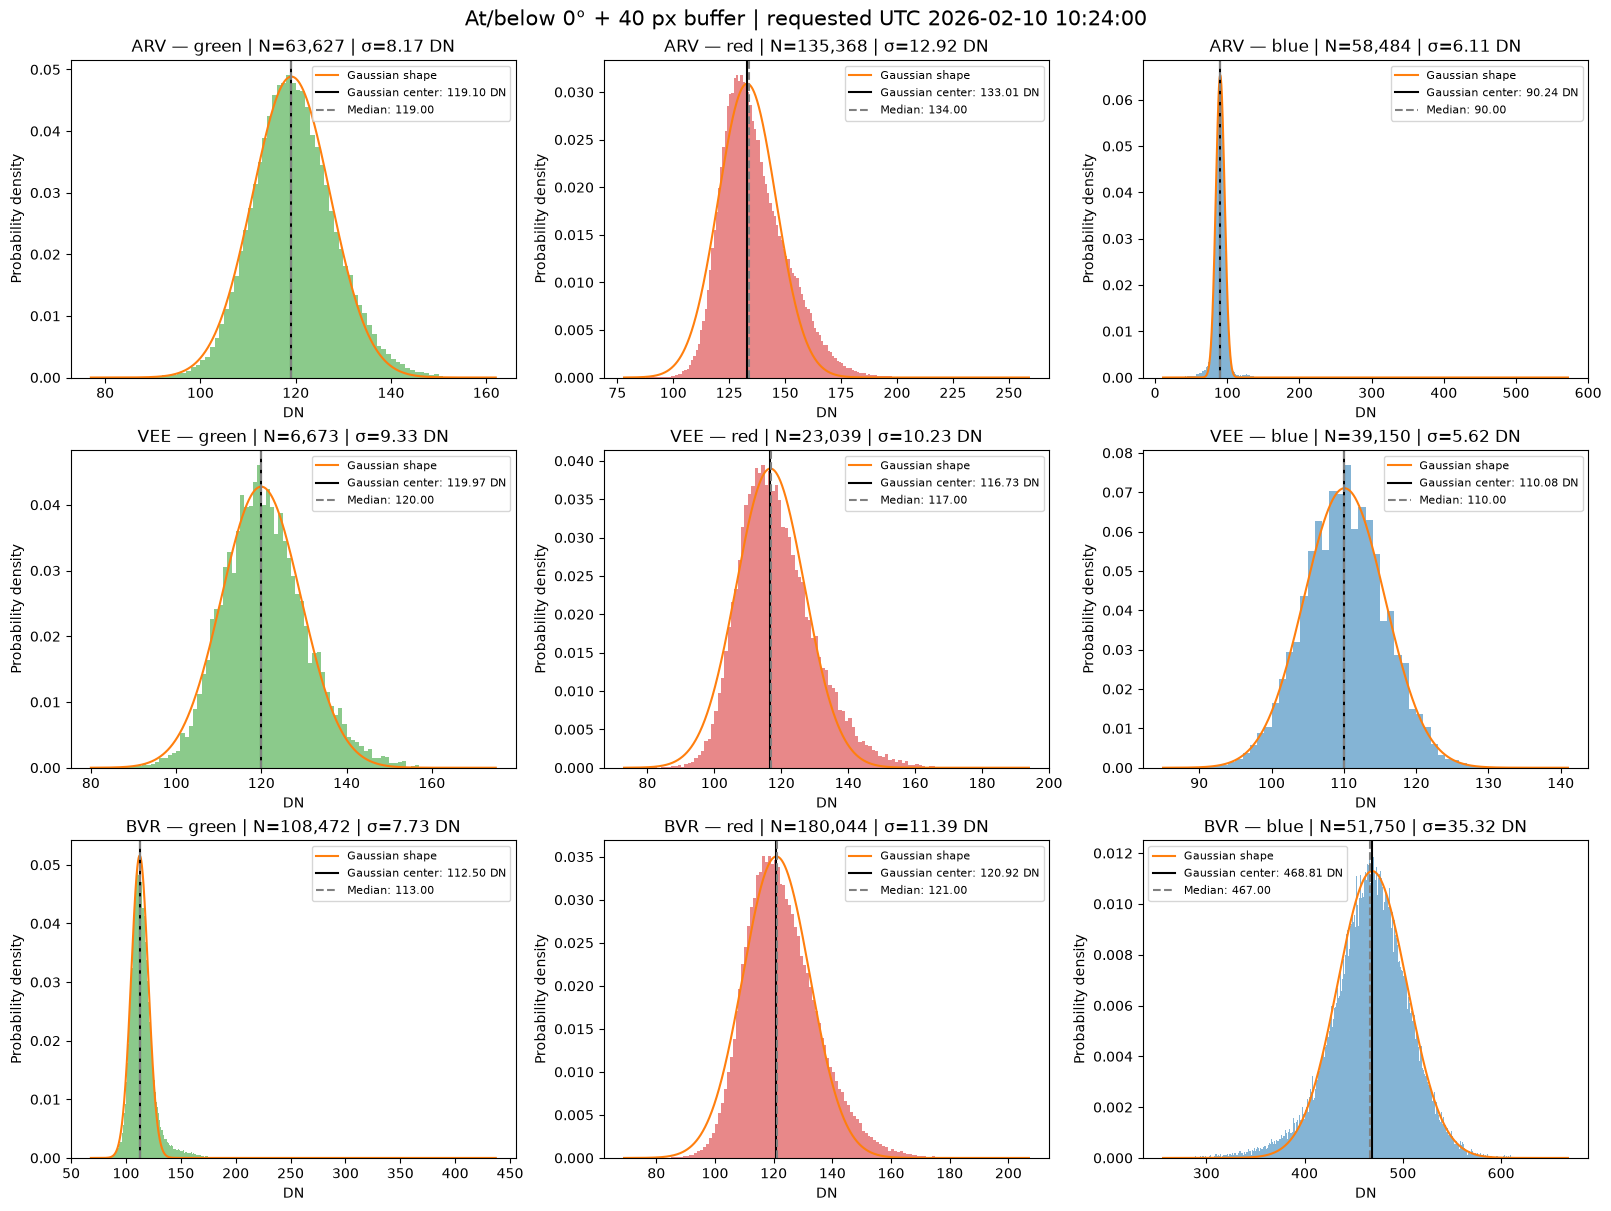

In [7]:
from core import generate_skymap

sites = ("ARV", "VEE", "BVR")
colors = ("green", "red", "blue")
experiment_results = {}
experiment_frames = {}
fig, axes = plt.subplots(3, 3, figsize=(16, 12), layout="constrained")
for row, site in enumerate(sites):
    for col, color in enumerate(colors):
        ax = axes[row, col]
        ax.set_title(f"{site} — {color}")
        ax.set_xlabel("DN")
        ax.set_ylabel("Probability density")
        try:
            # Read elevation directly: no geographic reprojection is needed.
            payload = getattr(generate_skymap, f"load_{site}")(color=color)
            elevation = np.asarray(payload[3], dtype=float)
            below_horizon = np.isfinite(elevation) & (elevation <= 0.0)
            sample_mask = calibration.buffered_corner_mask(below_horizon, 40.0)
            candidates = get_site_tiff_candidates(site, DATE, color, mission="GNEISS")
            if not candidates:
                raise FileNotFoundError("No TIFFs available")
            cadence = {"green": FRAME_INTERVAL_SECONDS_GREEN,
                       "red": FRAME_INTERVAL_SECONDS_RED, "blue": 0.90178}[color]
            image, _ = load_best_frame_from_tiffs(site, candidates, TARGET, cadence, color=color)
            image = np.asarray(image)
            if image.shape != sample_mask.shape:
                raise ValueError(f"Image/starmap shape mismatch: {image.shape} / {sample_mask.shape}")
            experiment_frames[(site, color)] = (image, elevation, below_horizon, sample_mask)
            estimate = calibration.estimate_corner_background(image, sample_mask)
            samples = calibration.finite_values(image[sample_mask])
            bins = np.arange(np.floor(samples.min()), np.ceil(samples.max()) + 1)
            if bins.size < 3:
                bins = np.linspace(samples.min(), samples.max() + 1, 3)
            ax.hist(samples, bins=bins, density=True, alpha=.55, color=f"tab:{color}")
            if not estimate["fit_failed"] and estimate["sigma"] > 0:
                x = np.linspace(bins[0], bins[-1], 1500)
                y = calibration.gauss(x, 1/(np.sqrt(2*np.pi)*estimate["sigma"]),
                                      estimate["center"], estimate["sigma"])
                ax.plot(x, y, color="tab:orange", label="Gaussian shape")
            method = "median fallback" if estimate["fit_failed"] else "Gaussian center"
            ax.axvline(estimate["center"], color="black", label=f"{method}: {estimate['center']:.2f} DN")
            ax.axvline(estimate["median"], color="gray", linestyle="--", label=f"Median: {estimate['median']:.2f}")
            ax.set_title(f"{site} — {color} | N={samples.size:,} | σ={estimate['sigma']:.2f} DN")
            ax.legend(fontsize=8)
            experiment_results[(site, color)] = estimate
        except (FileNotFoundError, OSError, ValueError, RuntimeError) as exc:
            experiment_results[(site, color)] = {"error": str(exc)}
            ax.text(.5, .5, str(exc), transform=ax.transAxes, ha="center", va="center", wrap=True, fontsize=9)
            print(f"{site} {color}: {exc}")
fig.suptitle(f"At/below 0° + 40 px buffer | requested UTC {TARGET}", fontsize=15)
plt.show()


## Raw DN images: horizon and 40-pixel background boundary

These are the same frames used in the histogram grid above. **Yellow** marks the 0° boundary; **magenta dashed** marks the edge of the background selection after the 40-pixel buffer. Background samples lie on the outer/corner side of the magenta boundary.

For starmaps clipped to 0°, yellow marks the boundary of the zero-valued region (a horizon proxy), since a continuous 0° contour is not resolved there. For maps containing negative elevations it is the actual 0° contour. Each raw image has its own 1st–99.7th percentile display stretch and DN colorbar; the pixel values are unchanged.

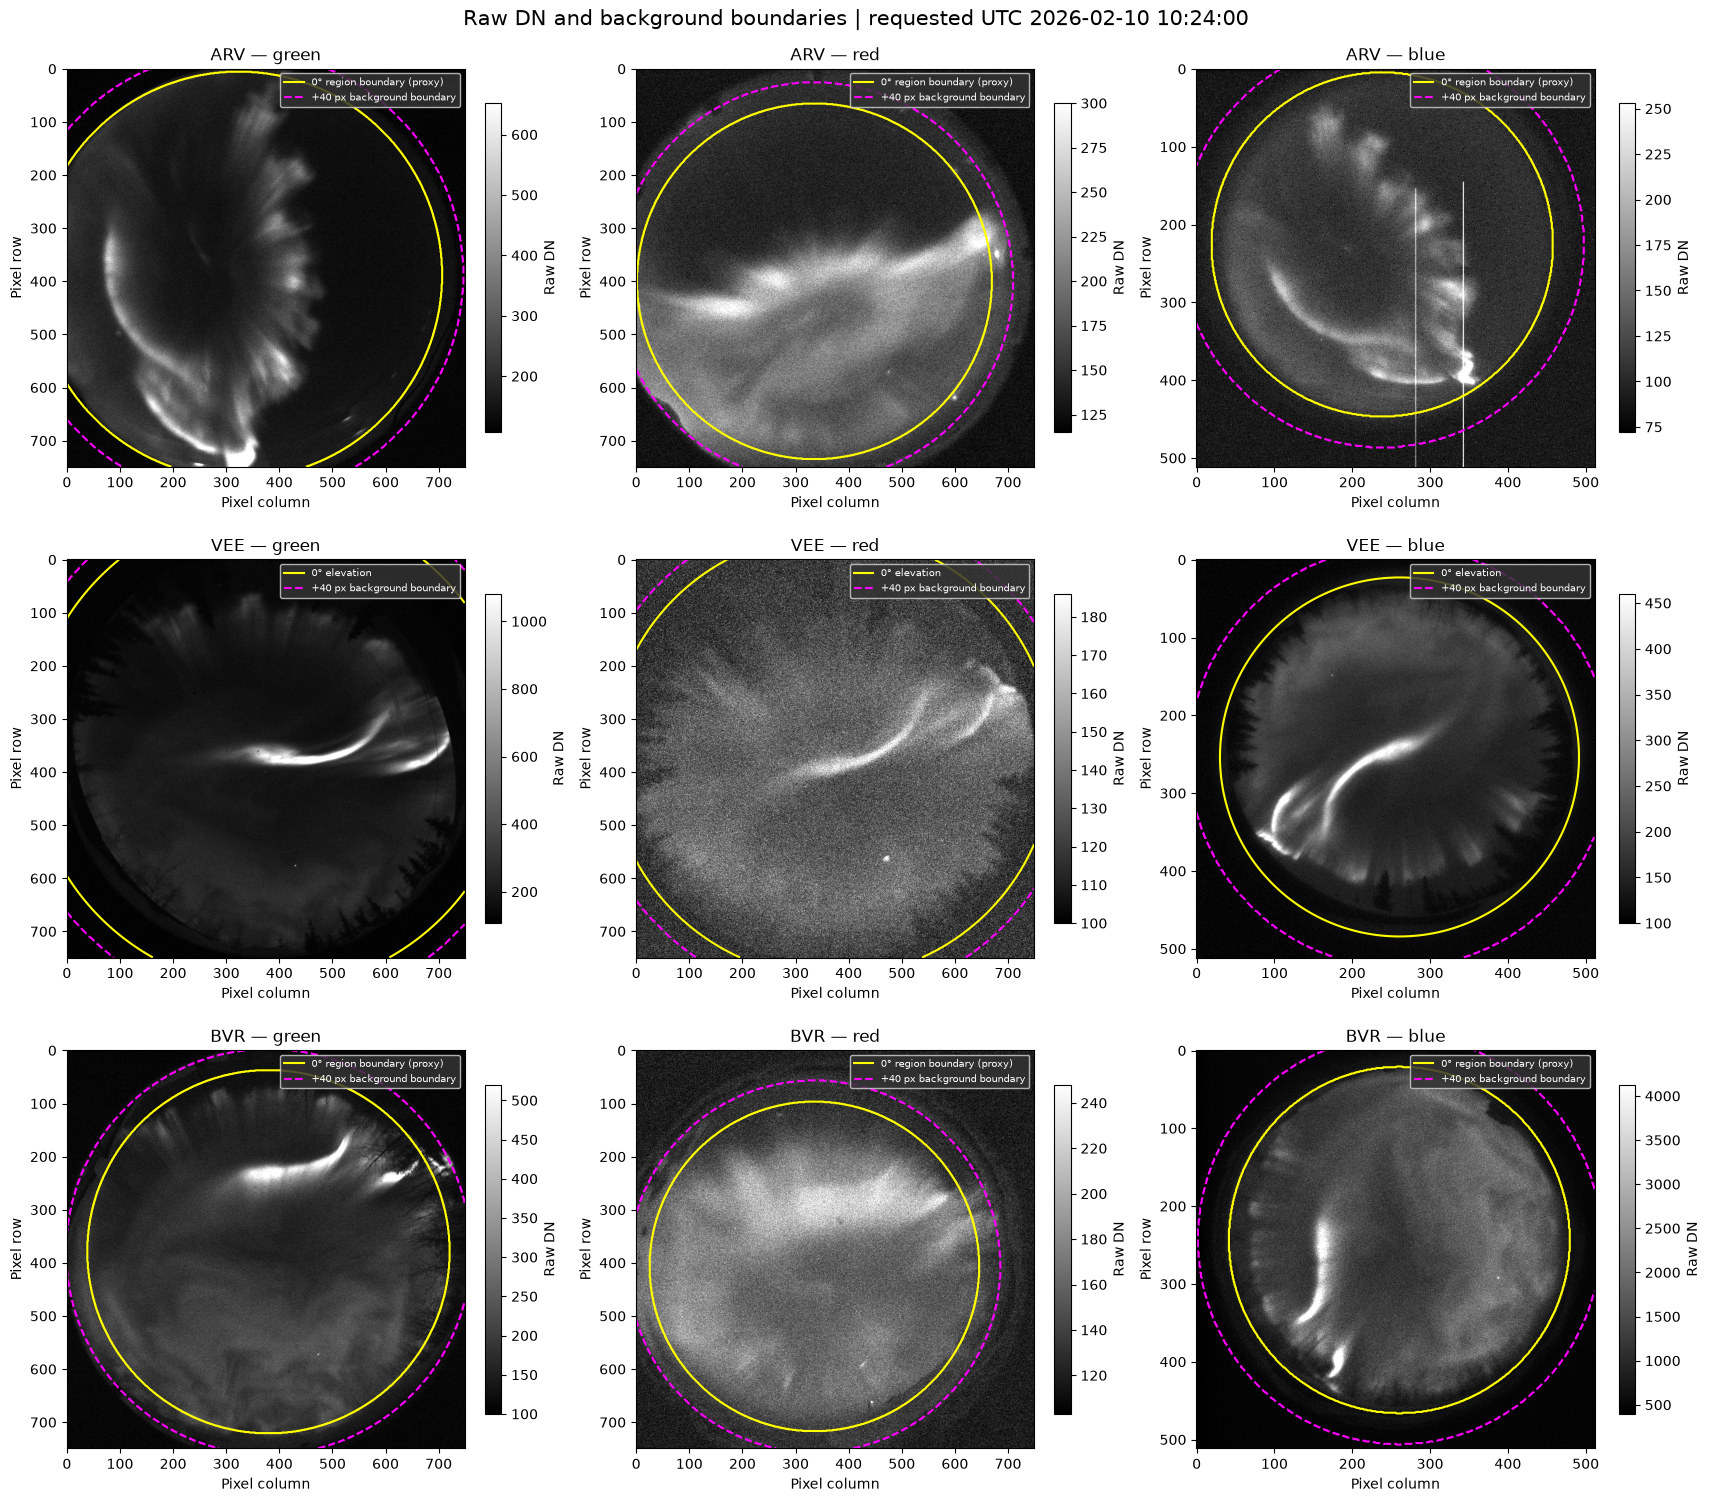

In [8]:
from matplotlib.lines import Line2D

fig, axes = plt.subplots(3, 3, figsize=(17, 15), layout="constrained")
for row, site in enumerate(sites):
    for col, color in enumerate(colors):
        ax = axes[row, col]
        ax.set_title(f"{site} — {color}")
        ax.set_xlabel("Pixel column")
        ax.set_ylabel("Pixel row")
        if (site, color) not in experiment_frames:
            message = experiment_results.get((site, color), {}).get("error", "No frame loaded; run the histogram cell first")
            ax.text(.5, .5, message, transform=ax.transAxes, ha="center", va="center", wrap=True)
            continue
        image, elevation, below_horizon, sample_mask = experiment_frames[(site, color)]
        finite = image[np.isfinite(image)]
        low, high = np.percentile(finite, [1, 99.7])
        im = ax.imshow(image, origin="upper", cmap="gray", vmin=low, vmax=high)
        fig.colorbar(im, ax=ax, label="Raw DN", shrink=.75)
        if np.any(np.isfinite(elevation) & (elevation < 0)):
            ax.contour(np.ma.masked_invalid(elevation), levels=[0], colors="yellow", linewidths=1.5)
            horizon_label = "0° elevation"
        else:
            ax.contour(below_horizon.astype(float), levels=[.5], colors="yellow", linewidths=1.5)
            horizon_label = "0° region boundary (proxy)"
        if np.any(sample_mask) and not np.all(sample_mask):
            ax.contour(sample_mask.astype(float), levels=[.5], colors="magenta", linewidths=1.5, linestyles="--")
        ax.legend(handles=[Line2D([], [], color="yellow", label=horizon_label),
                           Line2D([], [], color="magenta", linestyle="--", label="+40 px background boundary")],
                  loc="upper right", fontsize=7, facecolor="#333333", labelcolor="white", framealpha=.85)
fig.suptitle(f"Raw DN and background boundaries | requested UTC {TARGET}", fontsize=15)
plt.show()
